In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the hourly bike-sharing dataset
df = pd.read_csv("hour.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:

# Display all column names
print("Column names:")
print(df.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())


Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-nu

Target variable: cnt

Summary statistics:
count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

Number of unique rental counts:
869


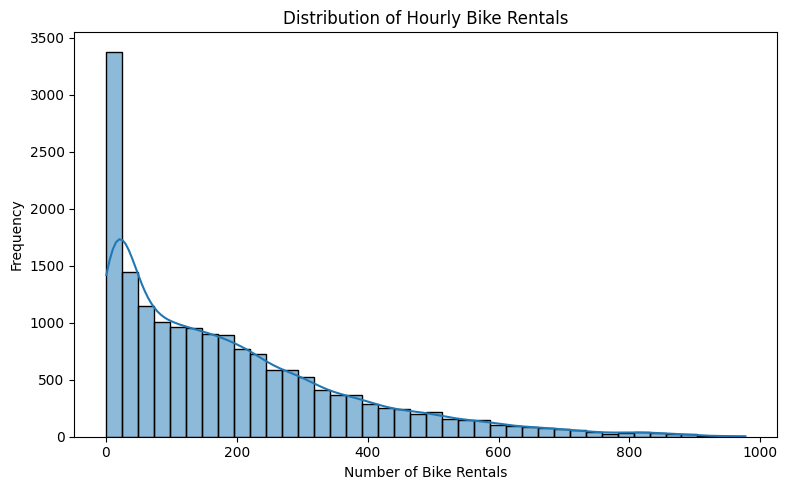

In [3]:

# Analyze the target variable: total bike rentals

print("Target variable: cnt")
print("\nSummary statistics:")
print(df["cnt"].describe())

print("\nNumber of unique rental counts:")
print(df["cnt"].nunique())

# Visualize the distribution of hourly rentals
plt.figure(figsize=(8, 5))
sns.histplot(df["cnt"], bins=40, kde=True)
plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Number of Bike Rentals")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


Average rentals by hour:
hr
0      53.90
1      33.38
2      22.87
3      11.73
4       6.35
5      19.89
6      76.04
7     212.06
8     359.01
9     219.31
10    173.67
11    208.14
12    253.32
13    253.66
14    240.95
15    251.23
16    311.98
17    461.45
18    425.51
19    311.52
20    226.03
21    172.31
22    131.34
23     87.83
Name: cnt, dtype: float64


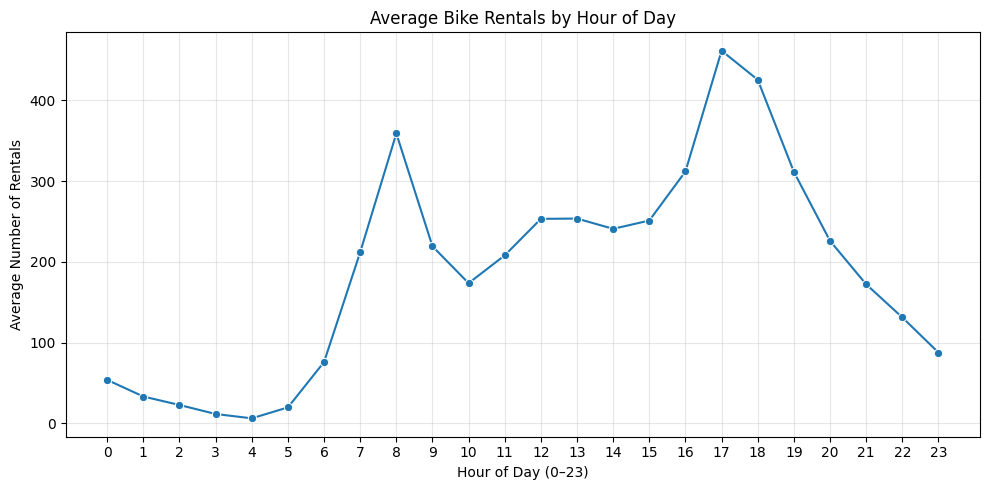

In [4]:

# Analyze average bike rentals by hour

hourly_demand = df.groupby("hr")["cnt"].mean()

print("Average rentals by hour:")
print(hourly_demand.round(2))

plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly_demand.index, y=hourly_demand.values, marker="o")
plt.title("Average Bike Rentals by Hour of Day")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Average rentals by day type:
workingday
0    181.41
1    193.21
Name: cnt, dtype: float64


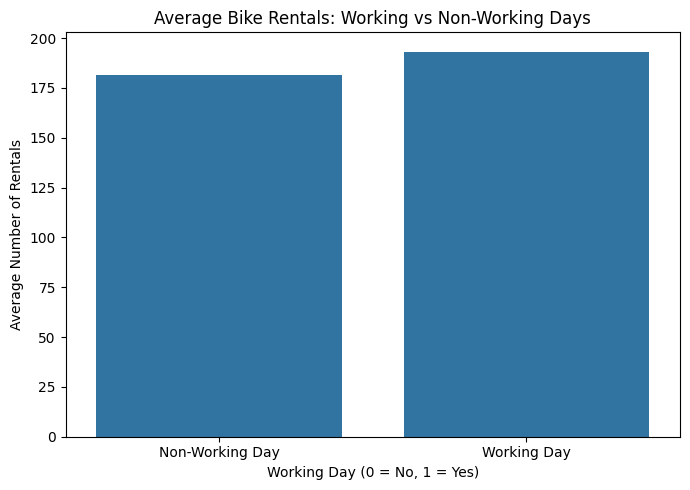

In [5]:

# Compare bike rentals on working and non-working days

working_demand = df.groupby("workingday")["cnt"].mean()

print("Average rentals by day type:")
print(working_demand.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(x=working_demand.index, y=working_demand.values)

plt.title("Average Bike Rentals: Working vs Non-Working Days")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Average Number of Rentals")
plt.xticks([0, 1], ["Non-Working Day", "Working Day"])
plt.tight_layout()
plt.show()


Average rentals by weather condition:
weathersit
1    204.87
2    175.17
3    111.58
4     74.33
Name: cnt, dtype: float64


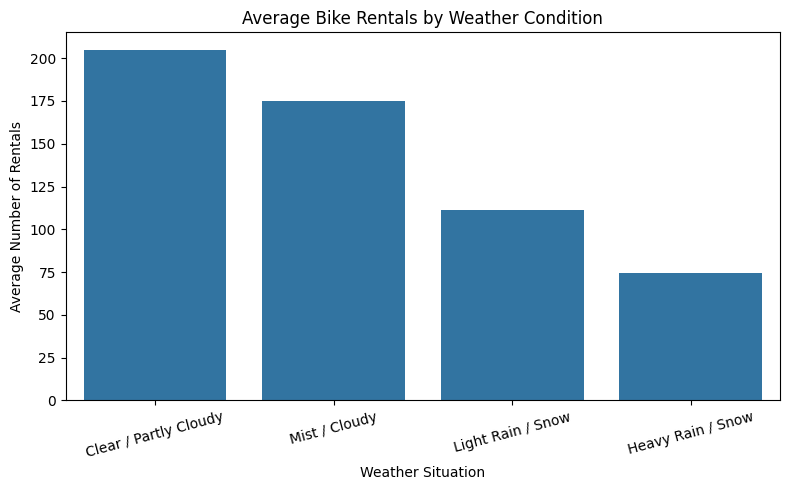

In [6]:

# Analyze average rentals by weather condition

weather_demand = df.groupby("weathersit")["cnt"].mean()

print("Average rentals by weather condition:")
print(weather_demand.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(x=weather_demand.index, y=weather_demand.values)

plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather Situation")
plt.ylabel("Average Number of Rentals")
plt.xticks(
    ticks=range(len(weather_demand)),
    labels=[
        "Clear / Partly Cloudy",
        "Mist / Cloudy",
        "Light Rain / Snow",
        "Heavy Rain / Snow"
    ][:len(weather_demand)],
    rotation=15
)
plt.tight_layout()
plt.show()


In [7]:

# Convert date column to datetime
df["dteday"] = pd.to_datetime(df["dteday"])

# Sort data chronologically
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)

# Check the date range
print("Start date:", df["dteday"].min())
print("End date:", df["dteday"].max())

# Verify chronological order
print("\nFirst 5 dates and hours:")
display(df[["dteday", "hr", "cnt"]].head())

print("\nData preparation completed!")


Start date: 2011-01-01 00:00:00
End date: 2012-12-31 00:00:00

First 5 dates and hours:


,dteday,hr,cnt
0,2011-01-01,0,16
1,2011-01-01,1,40
2,2011-01-01,2,32
3,2011-01-01,3,13
4,2011-01-01,4,1



Data preparation completed!


In [8]:

# Select the target variable
y = df["cnt"]

# Select input features
features = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

X = df[features]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nTarget preview:")
print(y.head())


Feature shape: (17379, 12)
Target shape: (17379,)

Selected features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

Target preview:
0    16
1    40
2    32
3    13
4     1
Name: cnt, dtype: int64


In [9]:

# Split the data chronologically: 80% training, 20% testing

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining period:")
print(df["dteday"].iloc[0], "to", df["dteday"].iloc[split_index - 1])

print("\nTesting period:")
print(df["dteday"].iloc[split_index], "to", df["dteday"].iloc[-1])


Training features: (13903, 12)
Testing features: (3476, 12)

Training period:
2011-01-01 00:00:00 to 2012-08-07 00:00:00

Testing period:
2012-08-07 00:00:00 to 2012-12-31 00:00:00


In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict the training-set average for every test observation
baseline_prediction = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

# Evaluate baseline predictions
baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction))

print("Baseline Model Results")
print("----------------------")
print(f"Training mean rentals: {y_train.mean():.2f}")
print(f"MAE: {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")


Baseline Model Results
----------------------
Training mean rentals: 174.64
MAE: 174.98
RMSE: 232.61


In [11]:

from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train using historical data
rf_model.fit(X_train, y_train)

# Predict bike rentals for the test period
rf_prediction = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_prediction)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_prediction))

print("Random Forest Results")
print("---------------------")
print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")


Random Forest Results
---------------------
MAE: 45.00
RMSE: 69.82


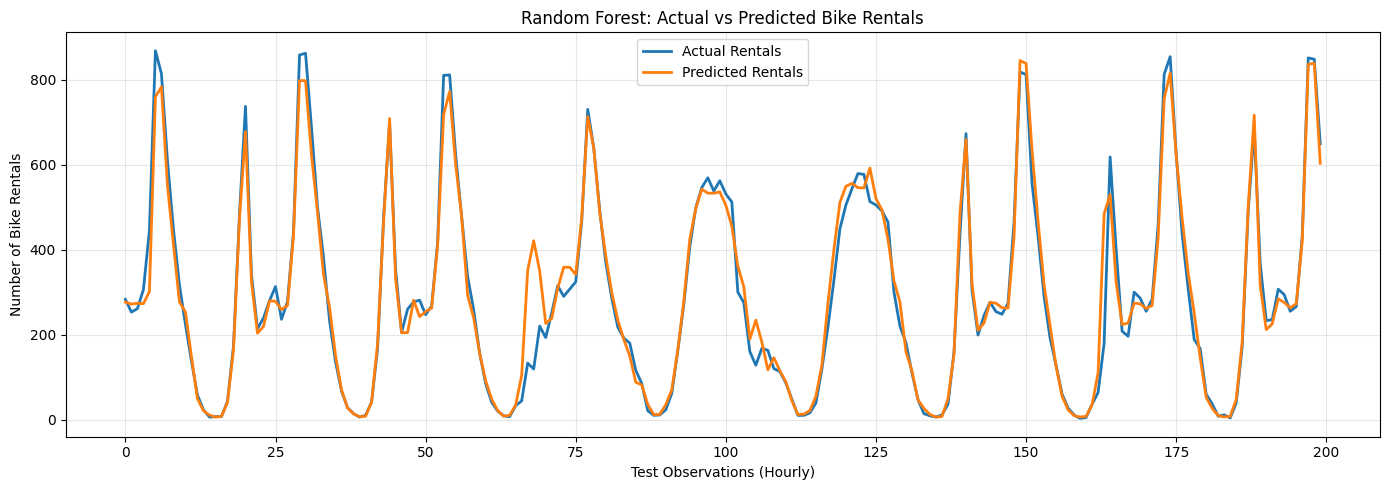

In [12]:

# Compare actual and predicted bike rentals

plt.figure(figsize=(14, 5))

plt.plot(
    y_test.iloc[:200].values,
    label="Actual Rentals",
    linewidth=2
)

plt.plot(
    rf_prediction[:200],
    label="Predicted Rentals",
    linewidth=2
)

plt.title("Random Forest: Actual vs Predicted Bike Rentals")
plt.xlabel("Test Observations (Hourly)")
plt.ylabel("Number of Bike Rentals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Feature Importance:
hr            0.6124
atemp         0.0857
temp          0.0811
yr            0.0693
workingday    0.0580
hum           0.0261
weathersit    0.0184
season        0.0132
mnth          0.0126
weekday       0.0124
windspeed     0.0089
holiday       0.0020
dtype: float64


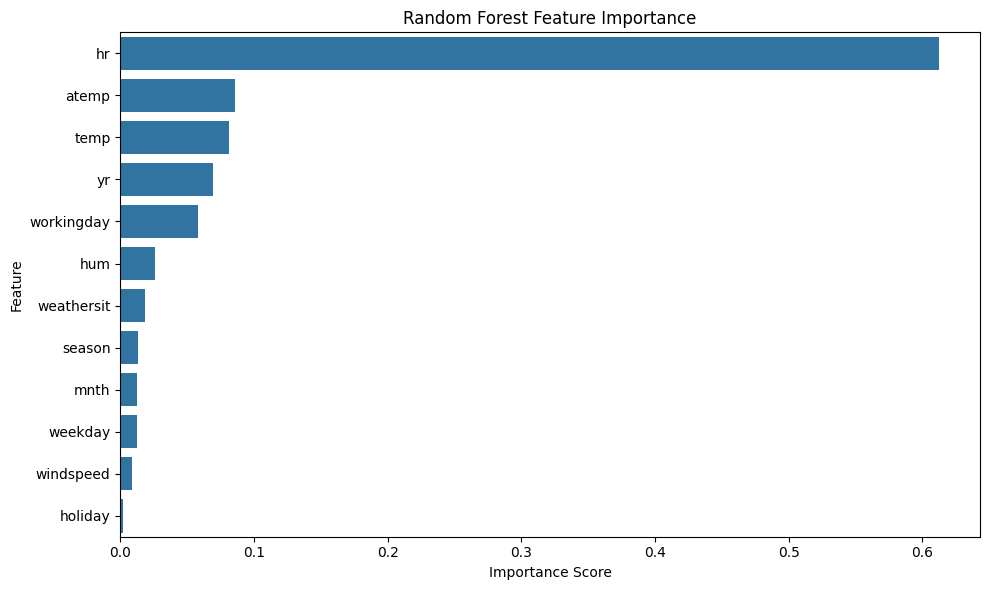

In [13]:

# Analyze feature importance

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(importance.round(4))

plt.figure(figsize=(10, 6))
sns.barplot(x=importance.values, y=importance.index)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


,Model,MAE,RMSE
0,Baseline,174.98,232.61
1,Random Forest,45.00,69.82


MAE improvement: 74.28%
RMSE improvement: 69.98%


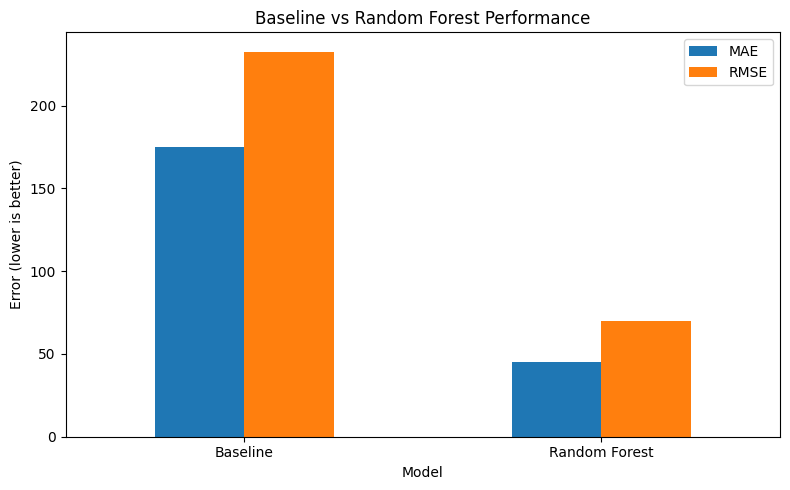

In [14]:

# Compare baseline and Random Forest performance

results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse]
})

display(results.round(2))

mae_improvement = (
    (baseline_mae - rf_mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - rf_rmse) / baseline_rmse
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Baseline vs Random Forest Performance")
plt.ylabel("Error (lower is better)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [15]:

from sklearn.ensemble import HistGradientBoostingRegressor

# Create the Gradient Boosting model
gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Predict on the same test set
gb_prediction = gb_model.predict(X_test)

# Evaluate the model
gb_mae = mean_absolute_error(y_test, gb_prediction)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_prediction))

print("Gradient Boosting Results")
print("-------------------------")
print(f"MAE: {gb_mae:.2f}")
print(f"RMSE: {gb_rmse:.2f}")


Gradient Boosting Results
-------------------------
MAE: 40.52
RMSE: 62.95


,Model,MAE,RMSE
0,Baseline,174.98,232.61
1,Random Forest,45.00,69.82
2,Gradient Boosting,40.52,62.95


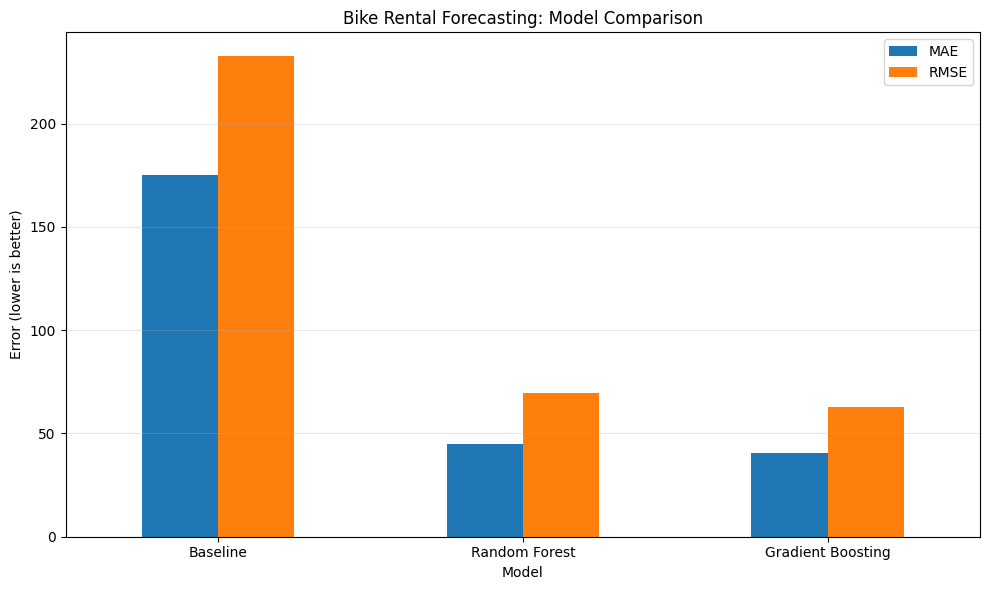

In [16]:

# Compare all models on the same test set

results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest", "Gradient Boosting"],
    "MAE": [baseline_mae, rf_mae, gb_mae],
    "RMSE": [baseline_rmse, rf_rmse, gb_rmse]
})

display(results.round(2))

# Plot the error comparison
results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Bike Rental Forecasting: Model Comparison")
plt.ylabel("Error (lower is better)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Prediction Error Summary
------------------------
         Error  Absolute Error
count  3476.00         3476.00
mean      9.65           40.52
std      62.22           48.18
min    -418.37            0.00
25%     -12.79            8.16
50%       3.82           22.53
75%      33.87           55.99
max     371.82          418.37

10 predictions with the largest errors:


,Actual,Predicted,Error,Absolute Error
2551,94,512.37,-418.37,418.37
3293,66,451.28,-385.28,385.28
1350,687,315.18,371.82,371.82
1987,115,481.68,-366.68,366.68
1349,715,348.81,366.19,366.19
2287,540,201.56,338.44,338.44
3340,31,355.63,-324.63,324.63
163,179,487.75,-308.75,308.75
1758,233,538.55,-305.55,305.55
1325,856,550.69,305.31,305.31


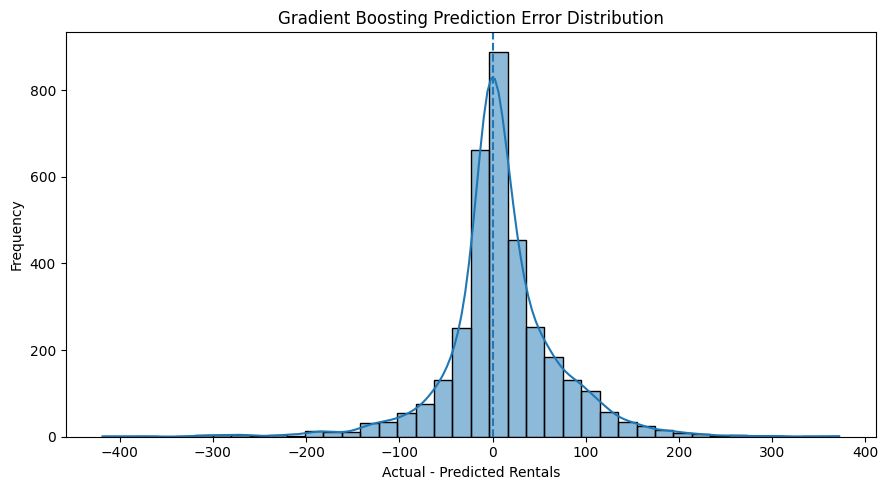

In [17]:

# Analyze prediction errors from Gradient Boosting

error_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": gb_prediction
})

error_df["Error"] = error_df["Actual"] - error_df["Predicted"]
error_df["Absolute Error"] = error_df["Error"].abs()

print("Prediction Error Summary")
print("------------------------")
print(error_df[["Error", "Absolute Error"]].describe().round(2))

print("\n10 predictions with the largest errors:")
display(
    error_df.sort_values(
        "Absolute Error", ascending=False
    ).head(10).round(2)
)

plt.figure(figsize=(9, 5))
sns.histplot(error_df["Error"], bins=40, kde=True)
plt.axvline(0, linestyle="--")
plt.title("Gradient Boosting Prediction Error Distribution")
plt.xlabel("Actual - Predicted Rentals")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [18]:

# Final model evaluation summary

final_results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest", "Gradient Boosting"],
    "MAE": [baseline_mae, rf_mae, gb_mae],
    "RMSE": [baseline_rmse, rf_rmse, gb_rmse]
})

best_model_name = final_results.loc[
    final_results["MAE"].idxmin(), "Model"
]

print("FINAL MODEL EVALUATION")
print("=" * 35)
display(final_results.round(2))

print("Best model by MAE:", best_model_name)
print(f"Best MAE: {final_results['MAE'].min():.2f}")
print(f"Best RMSE: {final_results.loc[final_results['Model'] == best_model_name, 'RMSE'].iloc[0]:.2f}")

print("\nImprovement over baseline:")
print(f"MAE: {((baseline_mae - gb_mae) / baseline_mae) * 100:.2f}%")
print(f"RMSE: {((baseline_rmse - gb_rmse) / baseline_rmse) * 100:.2f}%")


FINAL MODEL EVALUATION


,Model,MAE,RMSE
0,Baseline,174.98,232.61
1,Random Forest,45.00,69.82
2,Gradient Boosting,40.52,62.95


Best model by MAE: Gradient Boosting
Best MAE: 40.52
Best RMSE: 62.95

Improvement over baseline:
MAE: 76.84%
RMSE: 72.94%


In [19]:

import joblib
from pathlib import Path

# Create a folder for saved models
Path("models").mkdir(exist_ok=True)

# Save the trained model
joblib.dump(gb_model, "models/gradient_boosting_bike_demand.pkl")

# Save the feature names in the correct order
joblib.dump(features, "models/bike_demand_features.pkl")

print("Model saved successfully!")
print("Saved files:")
print("- models/gradient_boosting_bike_demand.pkl")
print("- models/bike_demand_features.pkl")


Model saved successfully!
Saved files:
- models/gradient_boosting_bike_demand.pkl
- models/bike_demand_features.pkl


In [20]:

import joblib
import pandas as pd

# Load the saved model and feature list
loaded_model = joblib.load(
    "models/gradient_boosting_bike_demand.pkl"
)

loaded_features = joblib.load(
    "models/bike_demand_features.pkl"
)

# Select one observation from the test data
sample = X_test.iloc[[0]][loaded_features]

# Predict bike rentals
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

print("Saved model loaded successfully!")
print(f"Actual bike rentals: {actual}")
print(f"Predicted bike rentals: {prediction:.2f}")
print(f"Absolute error: {abs(actual - prediction):.2f}")


Saved model loaded successfully!
Actual bike rentals: 283
Predicted bike rentals: 286.31
Absolute error: 3.31


In [21]:

import joblib
import pandas as pd

# Load the saved model and feature list
loaded_model = joblib.load(
    "models/gradient_boosting_bike_demand.pkl"
)

loaded_features = joblib.load(
    "models/bike_demand_features.pkl"
)

# Select one observation from the test data
sample = X_test.iloc[[0]][loaded_features]

# Predict bike rentals
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

print("Saved model loaded successfully!")
print(f"Actual bike rentals: {actual}")
print(f"Predicted bike rentals: {prediction:.2f}")
print(f"Absolute error: {abs(actual - prediction):.2f}")


Saved model loaded successfully!
Actual bike rentals: 283
Predicted bike rentals: 286.31
Absolute error: 3.31


In [22]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Build a PCA + Gradient Boosting pipeline
pca_model = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.95),
    HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        random_state=42
    )
)

# Train using only the training data
pca_model.fit(X_train, y_train)

# Predict on the same test set
pca_prediction = pca_model.predict(X_test)

# Evaluate performance
pca_mae = mean_absolute_error(y_test, pca_prediction)
pca_rmse = np.sqrt(mean_squared_error(y_test, pca_prediction))

# Find the number of retained components
pca_step = pca_model.named_steps["pca"]

print("PCA + Gradient Boosting Results")
print("--------------------------------")
print("Original features:", X_train.shape[1])
print("Retained components:", pca_step.n_components_)
print(
    "Explained variance retained:",
    f"{pca_step.explained_variance_ratio_.sum():.2%}"
)
print(f"MAE: {pca_mae:.2f}")
print(f"RMSE: {pca_rmse:.2f}")


PCA + Gradient Boosting Results
--------------------------------
Original features: 12
Retained components: 9
Explained variance retained: 95.24%
MAE: 113.22
RMSE: 165.90


In [23]:

# Check the boundary between training and testing data

split_index = len(X_train)

print("Last training observation:")
print(df.iloc[split_index - 1][["dteday", "hr"]])

print("\nFirst testing observation:")
print(df.iloc[split_index][["dteday", "hr"]])


Last training observation:
dteday    2012-08-07 00:00:00
hr                         11
Name: 13902, dtype: object

First testing observation:
dteday    2012-08-07 00:00:00
hr                         12
Name: 13903, dtype: object


In [24]:
# Check the chronological 80/20 split

split_index = int(len(df) * 0.8)

print("Last training observation:")
print(df.iloc[split_index - 1][["dteday", "hr"]])

print("\nFirst testing observation:")
print(df.iloc[split_index][["dteday", "hr"]])

Last training observation:
dteday    2012-08-07 00:00:00
hr                         11
Name: 13902, dtype: object

First testing observation:
dteday    2012-08-07 00:00:00
hr                         12
Name: 13903, dtype: object


In [25]:
import pandas as pd

df = pd.read_csv("hour.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (17379, 17)
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


In [26]:
split_index = int(len(df) * 0.8)

print("Last training observation:")
print(df.iloc[split_index - 1][["dteday", "hr"]])

print("\nFirst testing observation:")
print(df.iloc[split_index][["dteday", "hr"]])

Last training observation:
dteday    2012-08-07
hr                11
Name: 13902, dtype: object

First testing observation:
dteday    2012-08-07
hr                12
Name: 13903, dtype: object


In [27]:
# Ensure dates are in datetime format
df["dteday"] = pd.to_datetime(df["dteday"])

# Sort observations chronologically
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)

# Split using complete dates
unique_dates = sorted(df["dteday"].unique())
split_date = unique_dates[int(len(unique_dates) * 0.8)]

train_df = df[df["dteday"] < split_date].copy()
test_df = df[df["dteday"] >= split_date].copy()

print("Split date:", split_date)
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("Last training date:", train_df["dteday"].max())
print("First testing date:", test_df["dteday"].min())

Split date: 2012-08-07 00:00:00
Training shape: (13891, 17)
Testing shape: (3488, 17)
Last training date: 2012-08-06 00:00:00
First testing date: 2012-08-07 00:00:00


In [28]:
# Select input features (exclude data leakage columns)
features = [
    "season", "yr", "mnth", "hr", "holiday",
    "weekday", "workingday", "weathersit",
    "temp", "atemp", "hum", "windspeed"
]

target = "cnt"

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (13891, 12)
X_test: (3488, 12)
y_train: (13891,)
y_test: (3488,)


In [29]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train the Gradient Boosting model
gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

gb_model.fit(X_train, y_train)

# Generate predictions
y_pred = gb_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Gradient Boosting Model Evaluation")
print("---------------------------------")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

Gradient Boosting Model Evaluation
---------------------------------
MAE: 42.28
RMSE: 65.04


In [30]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    gb_model,
    "models/gradient_boosting_bike_demand.pkl"
)

joblib.dump(
    features,
    "models/bike_demand_features.pkl"
)

print("Updated model saved successfully!")
print("Updated feature list saved successfully!")

Updated model saved successfully!
Updated feature list saved successfully!


In [31]:
import joblib
import pandas as pd

# Load the saved model and feature list
loaded_model = joblib.load("models/gradient_boosting_bike_demand.pkl")
loaded_features = joblib.load("models/bike_demand_features.pkl")

# Predict demand for one test observation
sample = X_test[loaded_features].iloc[[0]]
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

print("Saved model loaded successfully!")
print(f"Actual bike demand: {actual}")
print(f"Predicted bike demand: {prediction:.2f}")
print(f"Absolute error: {abs(actual - prediction):.2f}")

Saved model loaded successfully!
Actual bike demand: 47
Predicted bike demand: 48.64
Absolute error: 1.64
